In [7]:
import ultralytics
import torch
import os

print("Ultralytics Version:", ultralytics.__version__)
print("PyTorch Version:", torch.__version__)
print("CUDA verfügbar:", torch.cuda.is_available())

Ultralytics Version: 8.4.216
PyTorch Version: 2.15.0+cpu
CUDA verfügbar: False


In [8]:
from ultralytics.data.utils import check_det_dataset

dataset_config = check_det_dataset("kitti.yaml")

print(dataset_config)


WARNING Dataset 'kitti.yaml' images not found, missing path 'C:\Users\Schil\5.Semester\datasets\kitti\images\val'
Unzipping C:\Users\Schil\5.Semester\datasets\kitti.zip to C:\Users\Schil\5.Semester\datasets\kitti...: 100% ━━━━━━━━━━━━ 14969/14969 353.0files/s 42.4s0.1ss
Dataset download success  (92.9s), saved to C:\Users\Schil\5.Semester\datasets

{'path': WindowsPath('C:/Users/Schil/5.Semester/datasets/kitti'), 'train': 'C:\\Users\\Schil\\5.Semester\\datasets\\kitti\\images\\train', 'val': 'C:\\Users\\Schil\\5.Semester\\datasets\\kitti\\images\\val', 'names': {0: 'car', 1: 'van', 2: 'truck', 3: 'pedestrian', 4: 'person_sitting', 5: 'cyclist', 6: 'tram', 7: 'misc'}, 'download': 'https://github.com/ultralytics/assets/releases/download/v0.0.0/kitti.zip', 'yaml_file': 'C:\\Users\\Schil\\5.Semester\\intelligence-engineering-5\\.venv\\Lib\\site-packages\\ultralytics\\cfg\\datasets\\kitti.yaml', 'nc': 8, 'channels': 3}


In [9]:
from pathlib import Path

# Pfad zum KITTI-Datensatz
dataset_path = Path(r"C:\Users\Schil\5.Semester\datasets\kitti")

# Verzeichnisstruktur anzeigen
for folder in ["images/train", "images/val", "labels/train", "labels/val"]:
    path = dataset_path / folder

    print(f"{folder}:")
    print(f"  Existiert: {path.exists()}")

    if path.exists():
        print(f"  Dateien: {len(list(path.iterdir()))}")

images/train:
  Existiert: True
  Dateien: 5985
images/val:
  Existiert: True
  Dateien: 1496
labels/train:
  Existiert: True
  Dateien: 5985
labels/val:
  Existiert: True
  Dateien: 1496


Datensatz gefunden: c:\Users\Schil\5.Semester\intelligence-engineering-5\data\raw\kitti
car            : 23026
van            : 2359
truck          : 871
pedestrian     : 3566
person_sitting : 186
cyclist        : 1275
tram           : 394
misc           : 765


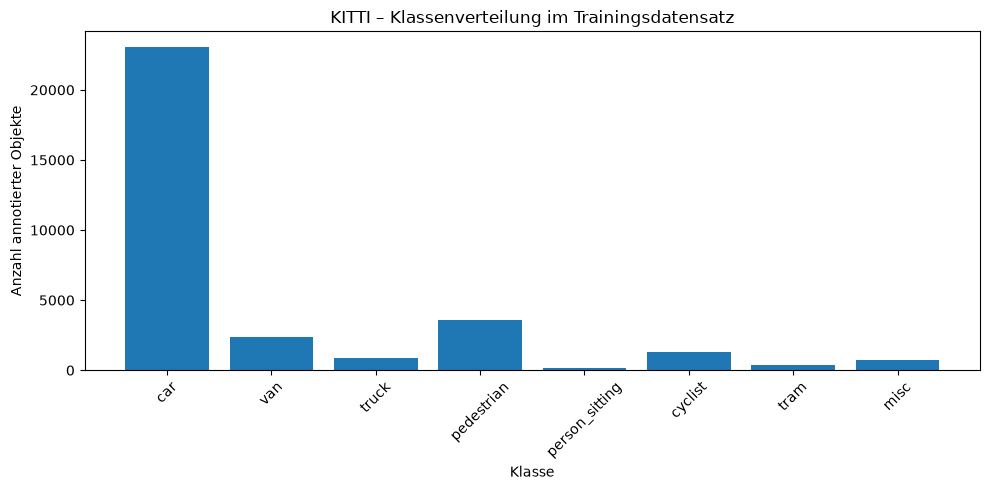

In [11]:
from collections import Counter
from pathlib import Path
import matplotlib.pyplot as plt

# Projektpfad ermitteln
project_root = Path.cwd()
dataset_path = project_root / "data" / "raw" / "kitti"

# Falls das Notebook aus dem Unterordner "notebooks" gestartet wird
if not dataset_path.exists():
    project_root = project_root.parent
    dataset_path = project_root / "data" / "raw" / "kitti"

# Prüfen, ob der Datensatz gefunden wurde
if not dataset_path.exists():
    raise FileNotFoundError(f"Datensatz nicht gefunden: {dataset_path}")

print("Datensatz gefunden:", dataset_path)

# Namen der Klassen
class_names = [
    "car",
    "van",
    "truck",
    "pedestrian",
    "person_sitting",
    "cyclist",
    "tram",
    "misc"
]

# Objektanzahl je Klasse zählen
class_counts = Counter()

for label_file in (dataset_path / "labels" / "train").glob("*.txt"):
    with open(label_file, "r") as file:
        for line in file:
            class_id = int(line.split()[0])
            class_counts[class_id] += 1

# Ergebnisse anzeigen
for class_id, class_name in enumerate(class_names):
    print(f"{class_name:15}: {class_counts[class_id]}")

# Diagramm erstellen
plt.figure(figsize=(10, 5))
plt.bar(class_names, [class_counts[i] for i in range(len(class_names))])
plt.title("KITTI – Klassenverteilung im Trainingsdatensatz")
plt.xlabel("Klasse")
plt.ylabel("Anzahl annotierter Objekte")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()